Initial inspection of a small part of the entire dataset - in particular the below data snippet is of precipitation in the year 2020 along with all the other required details

In [26]:
from pathlib import Path

RAW_DIR = (
    Path.home()
    / "Climate-Change-Awareness-Dashboard"
    / "precipitation"
    / "data"
    / "raw"
)

files = list(RAW_DIR.rglob("*.grd"))

for file in files:
    print(f"File: {file.name}")
    print(f"Location: {file}")
    print(f"Size: {file.stat().st_size:,} bytes")

File: 1923.grd
Location: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/data/raw/imd/1923.grd
Size: 25,425,900 bytes
File: 2012.grd
Location: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/data/raw/imd/2012.grd
Size: 25,495,560 bytes
File: 1990.grd
Location: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/data/raw/imd/1990.grd
Size: 25,425,900 bytes
File: 1985.grd
Location: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/data/raw/imd/1985.grd
Size: 25,425,900 bytes
File: 1956.grd
Location: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/data/raw/imd/1956.grd
Size: 25,495,560 bytes
File: 1939.grd
Location: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/data/raw/imd/1939.grd
Size: 25,425,900 bytes
File: 1957.grd
Location: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/data/raw/imd/1957.grd
Size: 25,425,900 bytes
File: 1987.grd
Location: /home/sharanya/Climate-Change-Awarene

In [27]:
import numpy as np

file_path = RAW_DIR / "imd" / "2020.grd"

rainfall = np.fromfile(file_path, dtype=np.float32)

rainfall = rainfall.reshape(366, 129, 135)

print("Shape:", rainfall.shape)
print("Data type:", rainfall.dtype)
print("Minimum:", np.min(rainfall))
print("Maximum:", np.max(rainfall))
print("Mean:", np.mean(rainfall))
print("Missing-value count:", np.sum(rainfall == -999))

Shape: (366, 129, 135)
Data type: float32
Minimum: -999.0
Maximum: 539.9128
Mean: -713.25
Missing-value count: 4557066


In [28]:
total = rainfall.size
missing = np.sum(rainfall == -999)
valid = rainfall[rainfall != -999]

print("Total values:", total)
print("Missing values:", missing)
print("Missing percentage:", round(missing / total * 100, 2))

print("Valid minimum:", valid.min())
print("Valid maximum:", valid.max())
print("Valid mean:", valid.mean())

Total values: 6373890
Missing values: 4557066
Missing percentage: 71.5
Valid minimum: 0.0
Valid maximum: 539.9128
Valid mean: 3.4876962


In [29]:
import pandas as pd

# First day of 2020
day_1 = rainfall[0]

df = pd.DataFrame(day_1)

output_path = RAW_DIR / "imd" / "2020_day1_preview.csv"

df.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/data/raw/imd/2020_day1_preview.csv


In [30]:
# Inspect the first day's rainfall values
print("First 10 x 10 grid values:")
print(rainfall[0, :10, :10])

# Count missing values on the first day
print("\nMissing values on first day:")
print(np.sum(rainfall[0] == -999))

# Check missing values across the entire year
missing_per_cell = np.sum(rainfall == -999, axis=0)

print("\nMissing values per grid cell across 2020:")
print("Minimum:", missing_per_cell.min())
print("Maximum:", missing_per_cell.max())
print("Average:", missing_per_cell.mean())

# Check how many grid cells have no missing values
print("\nGrid cells with no missing values:")
print(np.sum(missing_per_cell == 0))

First 10 x 10 grid values:
[[-999. -999. -999. -999. -999. -999. -999. -999. -999. -999.]
 [-999. -999. -999. -999. -999. -999. -999. -999. -999. -999.]
 [-999. -999. -999. -999. -999. -999. -999. -999. -999. -999.]
 [-999. -999. -999. -999. -999. -999. -999. -999. -999. -999.]
 [-999. -999. -999. -999. -999. -999. -999. -999. -999. -999.]
 [-999. -999. -999. -999. -999. -999. -999. -999. -999. -999.]
 [-999. -999. -999. -999. -999. -999. -999. -999. -999. -999.]
 [-999. -999. -999. -999. -999. -999. -999. -999. -999. -999.]
 [-999. -999. -999. -999. -999. -999. -999. -999. -999. -999.]
 [-999. -999. -999. -999. -999. -999. -999. -999. -999. -999.]]

Missing values on first day:
12451

Missing values per grid cell across 2020:
Minimum: 0
Maximum: 366
Average: 261.67476313522826

Grid cells with no missing values:
4964


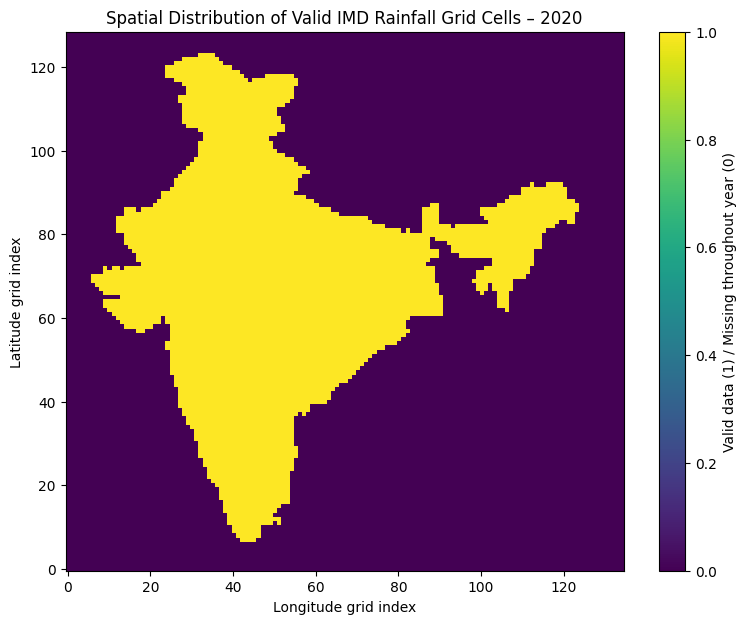

In [31]:
import matplotlib.pyplot as plt
import numpy as np

# A grid cell is valid if it has at least one non-missing value during 2020
valid_grid = np.any(rainfall != -999, axis=0)

plt.figure(figsize=(9, 7))
plt.imshow(valid_grid, origin="lower", aspect="auto", cmap="viridis")

plt.colorbar(label="Valid data (1) / Missing throughout year (0)")
plt.xlabel("Longitude grid index")
plt.ylabel("Latitude grid index")
plt.title("Spatial Distribution of Valid IMD Rainfall Grid Cells – 2020")

plt.show()

What this plot tells us:
- Yellow/bright regions: grid cells with rainfall data on at least one day.
- Dark regions: grid cells missing throughout the year.

Next code snippet tries to establish a proper coordinate system over the 2020 data so that the same can be applied to the larger dataset and can be meaningfully represented.

From the IMD's (indian meteorological department) the following Information was retrieved:
For this dataset:
- Latitude: 6.5°N to 38.5°N, in 0.25° increments (129 points).
- Longitude: 66.5°E to 100°E, in 0.25° increments (135 points).
- First grid point: 6.5°N, 66.5°E.
- Rainfall unit: millimetres (mm).

The below code snippet establishes the following:

- Lattitude and Longitude
- Every rainfall value associated with its date and coordinates
- missing values(purple region from the previous plot that does not have any rainfall data) excluded
- resultant dataset saved as a csv file

In [32]:
import numpy as np
import pandas as pd
from pathlib import Path

# 1. Generate IMD grid coordinates
latitudes = 6.5 + np.arange(129) * 0.25
longitudes = 66.5 + np.arange(135) * 0.25

# 2. Find all valid rainfall observations
day_idx, lat_idx, lon_idx = np.where(rainfall != -999.0)

# 3. Construct the structured dataset
df = pd.DataFrame({
    "date": pd.Timestamp("2020-01-01") + pd.to_timedelta(day_idx, unit="D"),
    "latitude": latitudes[lat_idx],
    "longitude": longitudes[lon_idx],
    "rainfall_mm": rainfall[day_idx, lat_idx, lon_idx]
})

# 4. Save the dataset in the interim folder
INTERIM_DIR = RAW_DIR.parent / "interim"
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

output_path = INTERIM_DIR / "imd_rainfall_2020.csv"
df.to_csv(output_path, index=False)

# 5. Inspect the result
print("Dataset shape:", df.shape)
print("\nFirst 10 rows:")
display(df.head(10))

print("\nDate range:", df["date"].min(), "to", df["date"].max())
print("Saved to:", output_path)

Dataset shape: (1816824, 4)

First 10 rows:


,date,latitude,longitude,rainfall_mm
0,2020-01-01,8.25,77.00,0.0
1,2020-01-01,8.25,77.25,0.0
2,2020-01-01,8.25,77.50,0.0
3,2020-01-01,8.25,77.75,0.0
4,2020-01-01,8.50,76.75,0.0
5,2020-01-01,8.50,77.00,0.0
6,2020-01-01,8.50,77.25,0.0
7,2020-01-01,8.50,77.50,0.0
8,2020-01-01,8.50,77.75,0.0
9,2020-01-01,8.50,78.00,0.0



Date range: 2020-01-01 00:00:00 to 2020-12-31 00:00:00
Saved to: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/data/interim/imd_rainfall_2020.csv


In [33]:
print("Total observations:", len(df))

print("Missing rainfall values:", (df["rainfall_mm"] == -999).sum())

print("Zero rainfall observations:", (df["rainfall_mm"] == 0).sum())

print("Minimum rainfall:", df["rainfall_mm"].min())

print("Maximum rainfall:", df["rainfall_mm"].max())

print("Actual NaN values:", df["rainfall_mm"].isna().sum())

Total observations: 1816824
Missing rainfall values: 0
Zero rainfall observations: 1245205
Minimum rainfall: 0.0
Maximum rainfall: 539.9128
Actual NaN values: 0


In [34]:

print("CSV size:", round(output_path.stat().st_size / (1024**2), 2), "MB")

display(df.head(20))

print("Number of unique dates:", df["date"].nunique())

print("First date:", df["date"].min())
print("Last date:", df["date"].max())

CSV size: 48.2 MB


,date,latitude,longitude,rainfall_mm
0,2020-01-01,8.25,77.00,0.0
1,2020-01-01,8.25,77.25,0.0
2,2020-01-01,8.25,77.50,0.0
3,2020-01-01,8.25,77.75,0.0
4,2020-01-01,8.50,76.75,0.0
5,2020-01-01,8.50,77.00,0.0
6,2020-01-01,8.50,77.25,0.0
7,2020-01-01,8.50,77.50,0.0
8,2020-01-01,8.50,77.75,0.0
9,2020-01-01,8.50,78.00,0.0


Number of unique dates: 366
First date: 2020-01-01 00:00:00
Last date: 2020-12-31 00:00:00


In [35]:
# Validate daily observation counts
daily_counts = df.groupby("date").size()

print("Minimum observations per day:", daily_counts.min())
print("Maximum observations per day:", daily_counts.max())
print("Number of unique daily counts:", daily_counts.nunique())

# Validate geographical coordinates
print("\nLatitude range:", df["latitude"].min(), "to", df["latitude"].max())
print("Longitude range:", df["longitude"].min(), "to", df["longitude"].max())

# Rainfall statistics
print("\nRainfall summary:")
print(df["rainfall_mm"].describe())

Minimum observations per day: 4964
Maximum observations per day: 4964
Number of unique daily counts: 1

Latitude range: 8.25 to 37.25
Longitude range: 68.0 to 97.25

Rainfall summary:
count    1.816824e+06
mean     3.487696e+00
std      1.154618e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      9.631887e-01
max      5.399128e+02
Name: rainfall_mm, dtype: float64


2020 was a leap year 366 days hence we also need to verify if the conversion code works right with the considered values, for non leap years hence we do the same process for the .grd file(binary file) of 2019

In [36]:
# Locate the 2019 rainfall file
file_2019 = RAW_DIR / "imd" / "2019.grd"

# Check file size
print("File size:", file_2019.stat().st_size, "bytes")

# Expected size for 365 days
expected_size = 365 * 129 * 135 * 4

print("Expected size:", expected_size, "bytes")
print("Size matches:", file_2019.stat().st_size == expected_size)

File size: 25425900 bytes
Expected size: 25425900 bytes
Size matches: True


In [37]:
rainfall_2019 = np.fromfile(file_2019, dtype=np.float32)

rainfall_2019 = rainfall_2019.reshape(365, 129, 135)

print("Shape:", rainfall_2019.shape)
print("Minimum:", rainfall_2019[rainfall_2019 != -999].min())
print("Maximum:", rainfall_2019[rainfall_2019 != -999].max())
print("Missing values:", np.sum(rainfall_2019 == -999))

Shape: (365, 129, 135)


Minimum: 0.0
Maximum: 487.10498
Missing values: 4544615


In [38]:
def convert_imd_file(year):

    file_path = RAW_DIR / "imd" / f"{year}.grd"

    days = 366 if pd.Timestamp(year=year, month=12, day=31).dayofyear == 366 else 365

    data = np.fromfile(file_path, dtype=np.float32)

    data = data.reshape(days, 129, 135)

    day_idx, lat_idx, lon_idx = np.where(data != -999)

    df_year = pd.DataFrame({
        "date": pd.Timestamp(f"{year}-01-01") + pd.to_timedelta(day_idx, unit="D"),
        "latitude": latitudes[lat_idx],
        "longitude": longitudes[lon_idx],
        "rainfall_mm": data[day_idx, lat_idx, lon_idx]
    })

    output_dir = RAW_DIR.parent / "interim"
    output_dir.mkdir(parents=True, exist_ok=True)

    output_path = output_dir / f"imd_rainfall_{year}.csv"

    df_year.to_csv(output_path, index=False)

    print(f"{year}: {len(df_year):,} observations saved.")

    return df_year

In [39]:
df_2019 = convert_imd_file(2019)

2019: 1,811,860 observations saved.


In [40]:
print("Dataset shape:", df_2019.shape)

print("\nDate range:")
print(df_2019["date"].min(), "to", df_2019["date"].max())

print("\nUnique dates:", df_2019["date"].nunique())

print("\nMissing values:")
print(df_2019.isna().sum())

print("\nFirst 5 rows:")
display(df_2019.head())

Dataset shape: (1811860, 4)

Date range:
2019-01-01 00:00:00 to 2019-12-31 00:00:00

Unique dates: 365

Missing values:
date           0
latitude       0
longitude      0
rainfall_mm    0
dtype: int64

First 5 rows:


,date,latitude,longitude,rainfall_mm
0,2019-01-01,8.25,77.00,0.0
1,2019-01-01,8.25,77.25,0.0
2,2019-01-01,8.25,77.50,0.0
3,2019-01-01,8.25,77.75,0.0
4,2019-01-01,8.50,76.75,0.0


Final conversion of entire dataset:

In [41]:
def convert_imd_file(year):

    file_path = RAW_DIR / "imd" / f"{year}.grd"

    # Determine number of days
    days = 366 if pd.Timestamp(year=year, month=12, day=31).dayofyear == 366 else 365

    # Verify binary file size
    expected_size = days * 129 * 135 * 4

    if file_path.stat().st_size != expected_size:
        raise ValueError(f"Unexpected file size for {year}")

    # Read binary data
    data = np.fromfile(file_path, dtype=np.float32)
    data = data.reshape(days, 129, 135)

    # Extract valid observations
    day_idx, lat_idx, lon_idx = np.where(data != -999)

    df_year = pd.DataFrame({
        "date": pd.Timestamp(f"{year}-01-01") + pd.to_timedelta(day_idx, unit="D"),
        "latitude": latitudes[lat_idx],
        "longitude": longitudes[lon_idx],
        "rainfall_mm": data[day_idx, lat_idx, lon_idx]
    })

    # Save CSV
    output_dir = RAW_DIR.parent / "interim"
    output_dir.mkdir(parents=True, exist_ok=True)

    output_path = output_dir / f"imd_rainfall_{year}.csv"

    df_year.to_csv(output_path, index=False)

    print(f"{year}: {len(df_year):,} observations saved.")

    return output_path

In [42]:
imd_dir = RAW_DIR / "imd"
interim_dir = RAW_DIR.parent / "interim"

files = sorted(
    imd_dir.glob("*.grd"),
    key=lambda f: int(f.stem)
)

for file in files:

    year = int(file.stem)
    output_path = interim_dir / f"imd_rainfall_{year}.csv"

    # Skip files already converted
    if output_path.exists():
        print(f"{year}: Already converted. Skipping.")
        continue

    try:
        convert_imd_file(year)

    except Exception as e:
        print(f"{year}: ERROR - {e}")

1901: Already converted. Skipping.
1902: Already converted. Skipping.
1903: Already converted. Skipping.
1904: Already converted. Skipping.
1905: Already converted. Skipping.
1906: Already converted. Skipping.
1907: Already converted. Skipping.
1908: Already converted. Skipping.
1909: Already converted. Skipping.
1910: Already converted. Skipping.
1911: Already converted. Skipping.
1912: Already converted. Skipping.
1913: Already converted. Skipping.
1914: Already converted. Skipping.
1915: Already converted. Skipping.
1916: Already converted. Skipping.
1917: Already converted. Skipping.
1918: Already converted. Skipping.
1919: Already converted. Skipping.
1920: Already converted. Skipping.
1921: Already converted. Skipping.
1922: Already converted. Skipping.
1923: Already converted. Skipping.
1924: Already converted. Skipping.
1925: Already converted. Skipping.
1926: Already converted. Skipping.
1927: Already converted. Skipping.
1928: Already converted. Skipping.
1929: Already conver

In [44]:
# Locate the 2025 file
file_2025 = RAW_DIR / "imd" / "2025.grd"

# 2025 is not a leap year
days = 365

# Expected binary file size
expected_size = days * 129 * 135 * 4
actual_size = file_2025.stat().st_size

print("Actual file size:", actual_size)
print("Expected file size:", expected_size)
print("Size matches:", actual_size == expected_size)

if actual_size == expected_size:

    # Read and reshape
    rainfall_2025 = np.fromfile(file_2025, dtype=np.float32)
    rainfall_2025 = rainfall_2025.reshape(365, 129, 135)

    # Separate valid observations
    valid = rainfall_2025[rainfall_2025 != -999.0]

    print("\nShape:", rainfall_2025.shape)
    print("Total values:", rainfall_2025.size)
    print("Valid observations:", len(valid))
    print("Missing observations:", np.sum(rainfall_2025 == -999.0))

    print("\nRainfall statistics:")
    print("Minimum:", valid.min())
    print("Maximum:", valid.max())
    print("Mean:", valid.mean())

    # Check daily coverage
    daily_counts = np.sum(rainfall_2025 != -999.0, axis=(1, 2))

    print("\nDaily observations:")
    print("Minimum:", daily_counts.min())
    print("Maximum:", daily_counts.max())
    print("Unique daily counts:", np.unique(daily_counts))

else:
    print("\nUnexpected file size. Do not reshape or convert this file.")

Actual file size: 25425900
Expected file size: 25425900
Size matches: True

Shape: (365, 129, 135)
Total values: 6356475
Valid observations: 1811860
Missing observations: 4544615

Rainfall statistics:
Minimum: 0.0
Maximum: 469.21014
Mean: 3.4739623

Daily observations:
Minimum: 4964
Maximum: 4964
Unique daily counts: [4964]


In [46]:
interim_dir = RAW_DIR.parent / "interim"

csv_files = sorted(
    interim_dir.glob("imd_rainfall_*.csv"),
    key=lambda f: int(f.stem.split("_")[-1])
)

years_converted = [int(f.stem.split("_")[-1]) for f in csv_files]

print("Total CSV files:", len(csv_files))
print("First year:", min(years_converted))
print("Last year:", max(years_converted))

print("\nConverted years:")
print(years_converted)

# Check for missing years in the expected range
expected_years = set(range(1901, 2026))
missing_years = sorted(expected_years - set(years_converted))

print("\nMissing years:", missing_years)

Total CSV files: 125
First year: 1901
Last year: 2025

Converted years:
[1901, 1902, 1903, 1904, 1905, 1906, 1907, 1908, 1909, 1910, 1911, 1912, 1913, 1914, 1915, 1916, 1917, 1918, 1919, 1920, 1921, 1922, 1923, 1924, 1925, 1926, 1927, 1928, 1929, 1930, 1931, 1932, 1933, 1934, 1935, 1936, 1937, 1938, 1939, 1940, 1941, 1942, 1943, 1944, 1945, 1946, 1947, 1948, 1949, 1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

Missing years: []
